In [1]:
import uproot
# import NanoEvents and NanoAODSchema to read the NanoAOD files
from coffea.nanoevents import NanoEventsFactory, NanoAODSchema
import matplotlib.pyplot as plt
import numpy as np
import awkward as ak
import mplhep as hep
hep.style.use("CMS")

# Set default figure size
plt.rcParams["figure.figsize"] = (10, 6)

CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

COLOR_ALIASES = {
    "CMS_blue": CMAP_10[0],        # Blue
    "CMS_orange": CMAP_10[1],      # Orange
    "CMS_red": CMAP_10[2],         # Red
    "CMS_gray": CMAP_10[3],        # Gray
    "CMS_purple": CMAP_10[4],      # Purple
    "CMS_brown": CMAP_10[5],       # Brown
    "CMS_dark_orange": CMAP_10[6], # Dark Orange
    "CMS_beige": CMAP_10[7],       # Beige
    "CMS_dark_gray": CMAP_10[8],   # Dark Gray
    "CMS_light_blue": CMAP_10[9]   # Light Blue
}
CMS_blue = COLOR_ALIASES["CMS_blue"]
CMS_red = COLOR_ALIASES["CMS_red"]

In [2]:
filename = "muon_nano.root"
events = NanoEventsFactory.from_root(filename, schemaclass=NanoAODSchema).events()
events.fields

/home/mmarcheg/.local/micromamba/envs/pocket-coffea/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:205: RuntimeWarning: Missing cross-reference index for Electron_genPartIdx => GenPart
  warnings.warn(
/home/mmarcheg/.local/micromamba/envs/pocket-coffea/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:205: RuntimeWarning: Missing cross-reference index for Electron_jetIdx => Jet
  warnings.warn(
/home/mmarcheg/.local/micromamba/envs/pocket-coffea/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:205: RuntimeWarning: Missing cross-reference index for Electron_photonIdx => Photon
  warnings.warn(
/home/mmarcheg/.local/micromamba/envs/pocket-coffea/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:205: RuntimeWarning: Missing cross-reference index for LowPtElectron_electronIdx => Electron
  warnings.warn(
/home/mmarcheg/.local/micromamba/envs/pocket-coffea/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:2

['event',
 'SimTrack',
 'PFCand',
 'MergedSimCluster',
 'RecHitHGC',
 'TrackConv',
 'SimHitHGCHEF',
 'bunchCrossing',
 'CaloPart',
 'PFTICLCand',
 'luminosityBlock',
 'GenPart',
 'orbitNumber',
 'Track',
 'TrackingPart',
 'SimHitHGCHEB',
 'TrackDisp',
 'SimCluster',
 'GenVtx',
 'run',
 'SimHitHGCEE']

In [3]:
events.RecHitHGC.fields

['detId',
 'energy',
 'time',
 'MergedSimCluster_MatchIdx',
 'MergedSimCluster_MatchQual',
 'SimCluster_MatchIdx',
 'SimCluster_MatchQual',
 'x',
 'y',
 'z',
 'hitr',
 'MergedSimClusterNumMatch',
 'MergedSimClusterBestMatchIdx',
 'MergedSimClusterBestMatchQual',
 'SimClusterNumMatch',
 'SimClusterBestMatchIdx',
 'SimClusterBestMatchQual']

In [10]:
events.MergedSimCluster.fields

['allHitsHGCAL',
 'crossedBoundary',
 'hasHGCALHit',
 'isPileup',
 'isTrainable',
 'onHGCFrontFace',
 'bunchCrossing',
 'charge',
 'eventId',
 'nHits',
 'pdgId',
 'rawEventId',
 'trackId',
 'trackIdAtBoundary',
 'boundaryEnergy',
 'boundaryEnergyNoMu',
 'boundaryP4',
 'boundaryPmag',
 'boundaryPt',
 'eta',
 'impactPoint_eta',
 'impactPoint_phi',
 'impactPoint_t',
 'impactPoint_x',
 'impactPoint_y',
 'impactPoint_z',
 'lastPos_x',
 'lastPos_y',
 'lastPos_z',
 'mass',
 'phi',
 'pileupFraction',
 'pt',
 'sumHitEnergy',
 'SimCluster_MatchIdx',
 'SimCluster_MatchQual',
 'recEnergy',
 'SimClusterNumMatch']

In [4]:
nhits = ak.num(events.RecHitHGC.x)
print(np.mean(nhits), '+-', round(np.std(nhits), 1))

66677.2 +- 300.4


Text(0, 1, 'Events')

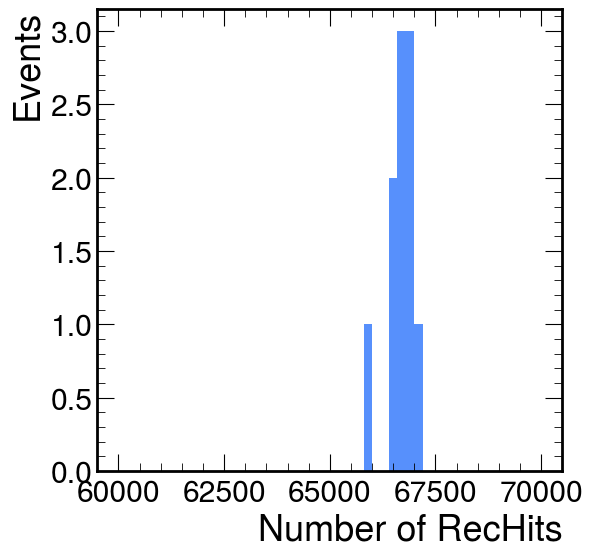

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.hist(nhits, bins=50, range=(60000, 70000))
ax.set_xlabel("Number of RecHits")
ax.set_ylabel("Events")

In [6]:
events.MergedSimCluster.eventId > 0

<Array [[False, False, False, ... True, True]] type='10 * var * bool'>

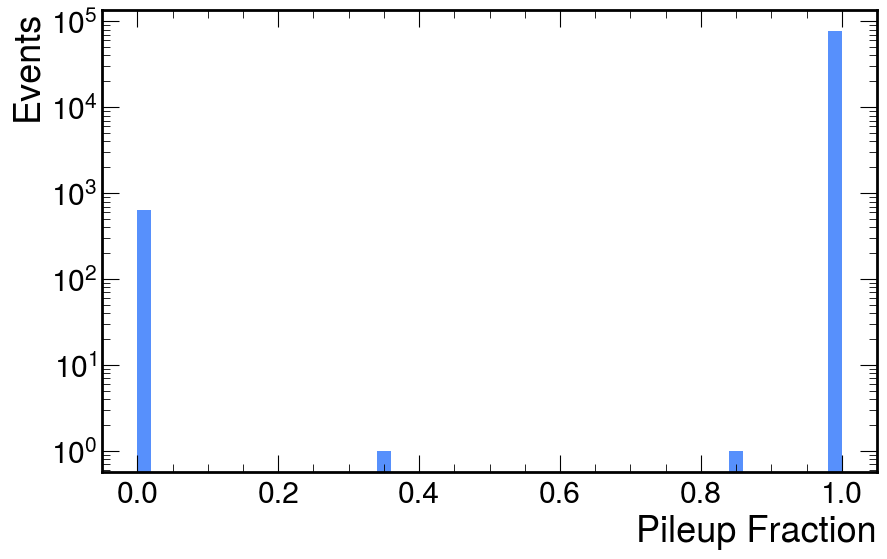

In [7]:
frac = ak.flatten(events.MergedSimCluster.pileupFraction)
plt.hist(frac, bins=50, range=(0, 1))
plt.xlabel("Pileup Fraction")
plt.ylabel("Events")
plt.yscale("log")
plt.show()

6280 9375
7742.3 +- 895.2
Pileup events: mean = 7622.4 +- 897.5
Hard scatter events: mean = 119.9 +- 18.9


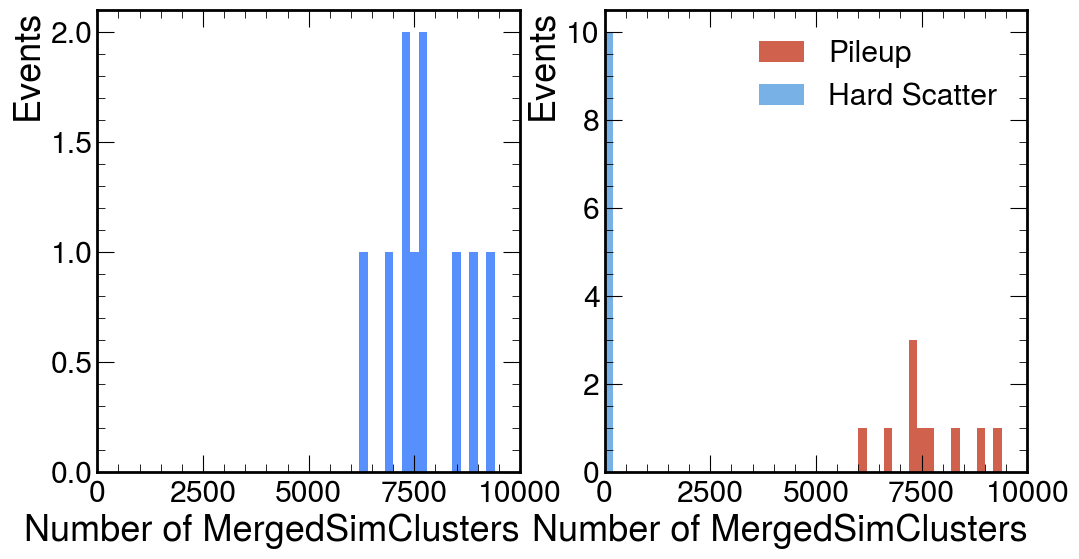

In [8]:
nclusters = ak.num(events.MergedSimCluster.impactPoint_x)
is_pileup = (events.MergedSimCluster.eventId > 0) | (events.MergedSimCluster.bunchCrossing > 0)
print(min(nclusters), max(nclusters))
print(np.mean(nclusters), '+-', round(np.std(nclusters), 1))
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
x_low, x_high = 0, 10000
ax[0].hist(nclusters, bins=50, range=(x_low, x_high))
ax[0].set_xlim(x_low, x_high)
ax[0].set_xlabel("Number of MergedSimClusters")
ax[0].set_ylabel("Events")
# Plot the distribution of nclusters for pileup and hard scatter events separately
ax[1].hist(ak.sum(is_pileup, axis=1), bins=50, range=(x_low, x_high), alpha=0.7, label='Pileup', color=CMS_red)
ax[1].hist(ak.sum(~is_pileup, axis=1), bins=50, range=(x_low, x_high), alpha=0.7, label='Hard Scatter', color=CMS_blue)
ax[1].set_xlim(x_low, x_high)
ax[1].set_xlabel("Number of MergedSimClusters")
ax[1].set_ylabel("Events")
ax[1].legend()
# Print number of merged sim clusters for pileup and hard scatter events
print("Pileup events: mean =", np.mean(ak.sum(is_pileup, axis=1)), "+-", round(np.std(ak.sum(is_pileup, axis=1)), 1))
print("Hard scatter events: mean =", np.mean(ak.sum(~is_pileup, axis=1)), "+-", round(np.std(ak.sum(~is_pileup, axis=1)), 1))

# Cluster energy distribution
Plots of MergedSimClusters energy distribution

## All events

0.7781629611032898 +- 1.8


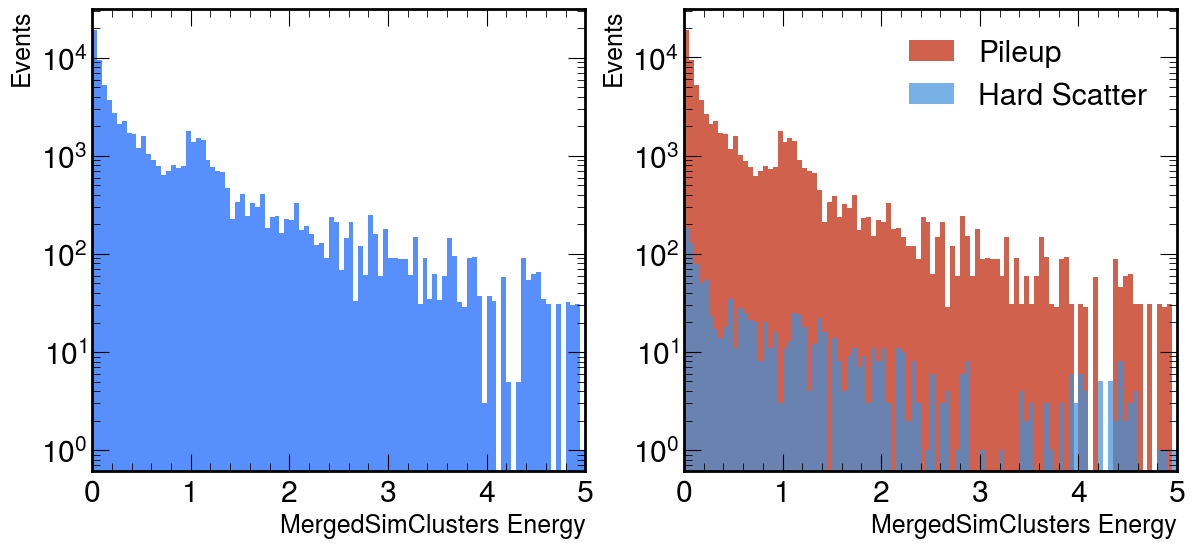

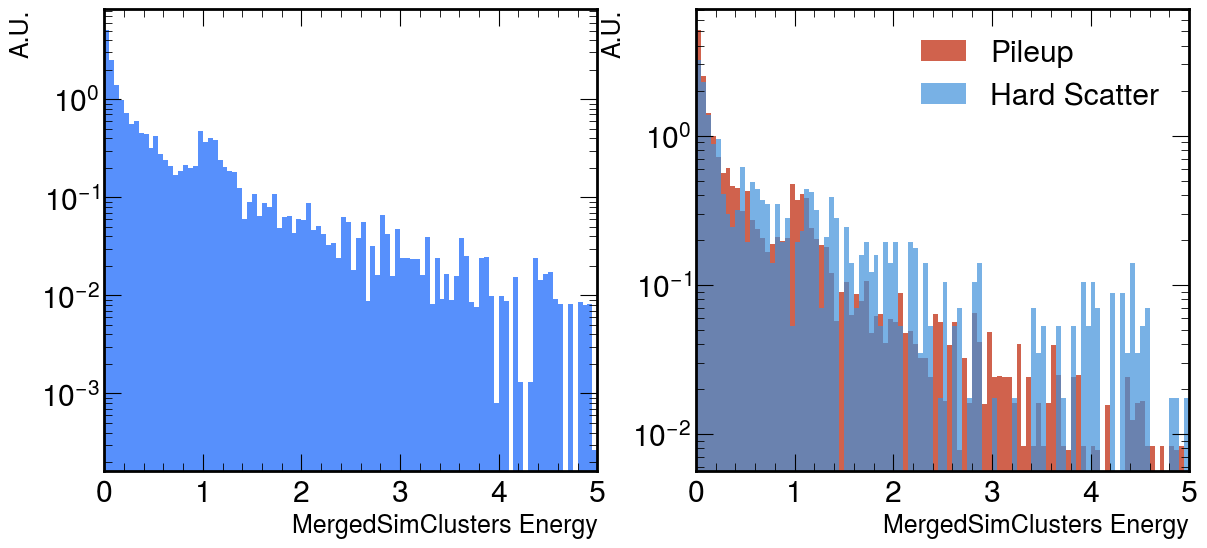

In [90]:
energy = events.MergedSimCluster.boundaryEnergy
is_pileup = (events.MergedSimCluster.eventId > 0) | (events.MergedSimCluster.bunchCrossing > 0)
print(np.mean(ak.flatten(energy)), '+-', round(np.std(ak.flatten(energy)), 1))
fontsize = 18
for density in [False, True]:
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    x_low, x_high = 0, 5.0
    nbins = 100
    ylabel = "A.U." if density else "Events"
    ax[0].hist(ak.flatten(energy), bins=nbins, range=(x_low, x_high), density=density)
    ax[0].set_xlim(x_low, x_high)
    ax[0].set_yscale("log")
    ax[0].set_xlabel("MergedSimClusters Energy", fontsize=fontsize)
    ax[0].set_ylabel(ylabel, fontsize=fontsize)
    # Plot the distribution of nclusters for pileup and hard scatter events separately
    ax[1].hist(ak.flatten(energy[is_pileup]), bins=nbins, range=(x_low, x_high), alpha=0.7, label='Pileup', color=CMS_red, density=density)
    ax[1].hist(ak.flatten(energy[~is_pileup]), bins=nbins, range=(x_low, x_high), alpha=0.7, label='Hard Scatter', color=CMS_blue, density=density)
    ax[1].set_xlim(x_low, x_high)
    ax[1].set_yscale("log")
    ax[1].set_xlabel("MergedSimClusters Energy", fontsize=fontsize)
    ax[1].set_ylabel(ylabel, fontsize=fontsize)
    ax[1].legend()
    # Print number of merged sim clusters for pileup and hard scatter events
    #print("Pileup events: mean =", np.mean(ak.sum(is_pileup, axis=1)), "+-", round(np.std(ak.sum(is_pileup, axis=1)), 1))
    #print("Hard scatter events: mean =", np.mean(ak.sum(~is_pileup, axis=1)), "+-", round(np.std(ak.sum(~is_pileup, axis=1)), 1))

## Single event

0.7876707429339171 +- 1.8


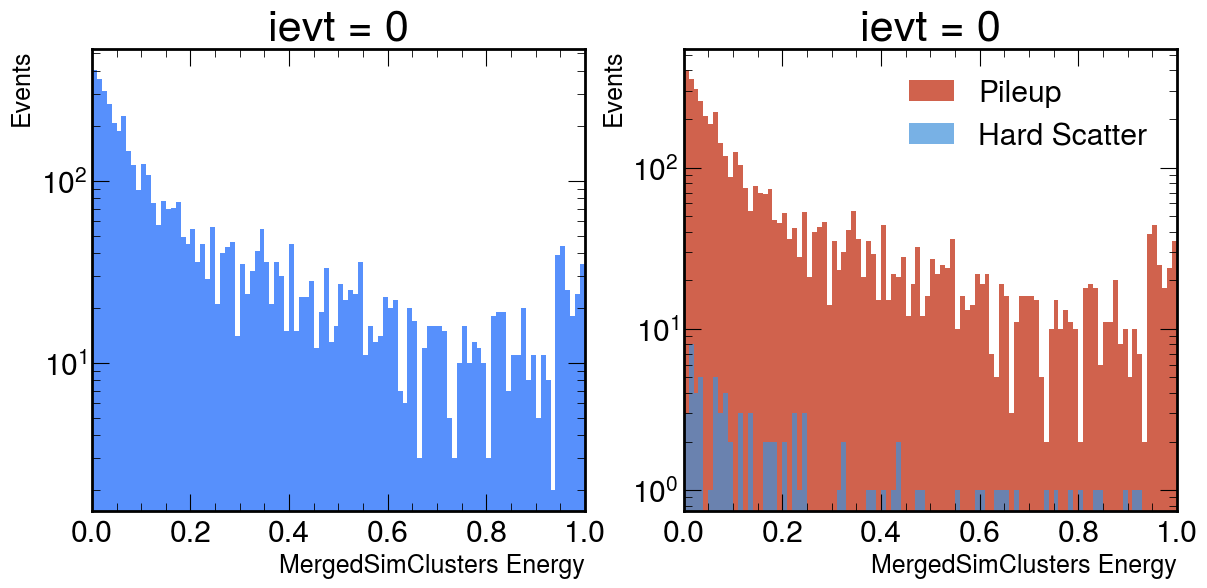

In [60]:
ievt = 0
energy = events.MergedSimCluster.boundaryEnergy[ievt]
is_pileup = (events.MergedSimCluster.eventId[ievt] > 0) | (events.MergedSimCluster.bunchCrossing[ievt] > 0)
nclusters = len(energy)
nclusters_pileup = len(energy[is_pileup])
print(np.mean(energy), '+-', round(np.std(energy), 1))
fontsize = 18
#for density in [False, True]:
for density in [False]:
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    nbins = 100
    x_low, x_high = 0, int(nbins / 100)
    ylabel = "A.U." if density else "Events"
    ax[0].hist(energy, bins=nbins, range=(x_low, x_high), density=density)
    ax[0].set_xlim(x_low, x_high)
    ax[0].set_yscale("log")
    ax[0].set_title(f"ievt = {ievt}")
    ax[0].set_xlabel("MergedSimClusters Energy", fontsize=fontsize)
    ax[0].set_ylabel(ylabel, fontsize=fontsize)
    # Plot the distribution of nclusters for pileup and hard scatter events separately
    n, bins, patches = ax[1].hist(energy[is_pileup], bins=nbins, range=(x_low, x_high), alpha=0.7, label='Pileup', color=CMS_red, density=density)
    ax[1].hist(energy[~is_pileup], bins=nbins, range=(x_low, x_high), alpha=0.7, label='Hard Scatter', color=CMS_blue, density=density)
    ax[1].set_xlim(x_low, x_high)
    ax[1].set_yscale("log")
    ax[1].set_title(f"ievt = {ievt}")
    ax[1].set_xlabel("MergedSimClusters Energy", fontsize=fontsize)
    ax[1].set_ylabel(ylabel, fontsize=fontsize)
    ax[1].legend()
    # Print number of merged sim clusters for pileup and hard scatter events
    #print("Pileup events: mean =", np.mean(ak.sum(is_pileup, axis=1)), "+-", round(np.std(ak.sum(is_pileup, axis=1)), 1))
    #print("Hard scatter events: mean =", np.mean(ak.sum(~is_pileup, axis=1)), "+-", round(np.std(ak.sum(~is_pileup, axis=1)), 1))

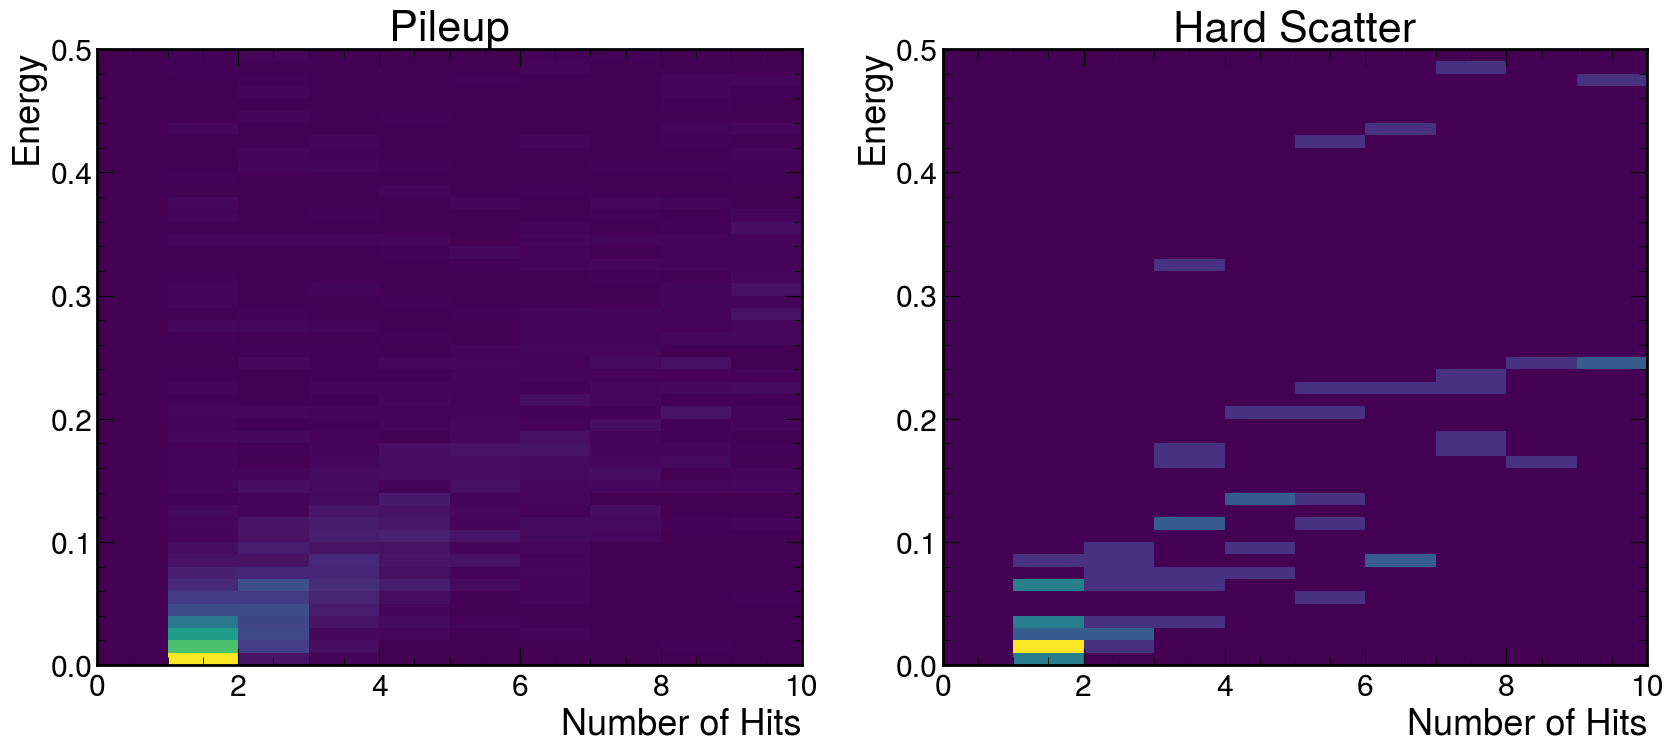

In [130]:
ievt = 0
is_pileup = (events.MergedSimCluster.eventId[ievt] > 0) | (events.MergedSimCluster.bunchCrossing[ievt] > 0)
energy = events.MergedSimCluster.boundaryEnergy[ievt].to_numpy()
nhits = events.MergedSimCluster.nHits[ievt].to_numpy()

fig, ax = plt.subplots(1, 2, figsize=[20,8])
for i, (mask, label) in enumerate(zip([is_pileup, ~is_pileup], ['Pileup', 'Hard Scatter'])):
    ax[i].hist2d(nhits[mask], energy[mask], range=((0, 10), (0, 0.5)), bins=(10, 50));
    ax[i].set_xlabel('Number of Hits')
    ax[i].set_ylabel('Energy')
    ax[i].set_title(label)

In [75]:
imax = 2
sum(n[0:imax]) / nclusters_pileup

0.12298682284040996

In [52]:
is_hard_scatter = ~is_pileup
ak.sum(is_hard_scatter, axis=1)

<Array [133, 114, 125, 125, ... 128, 158, 82] type='10 * int64'>

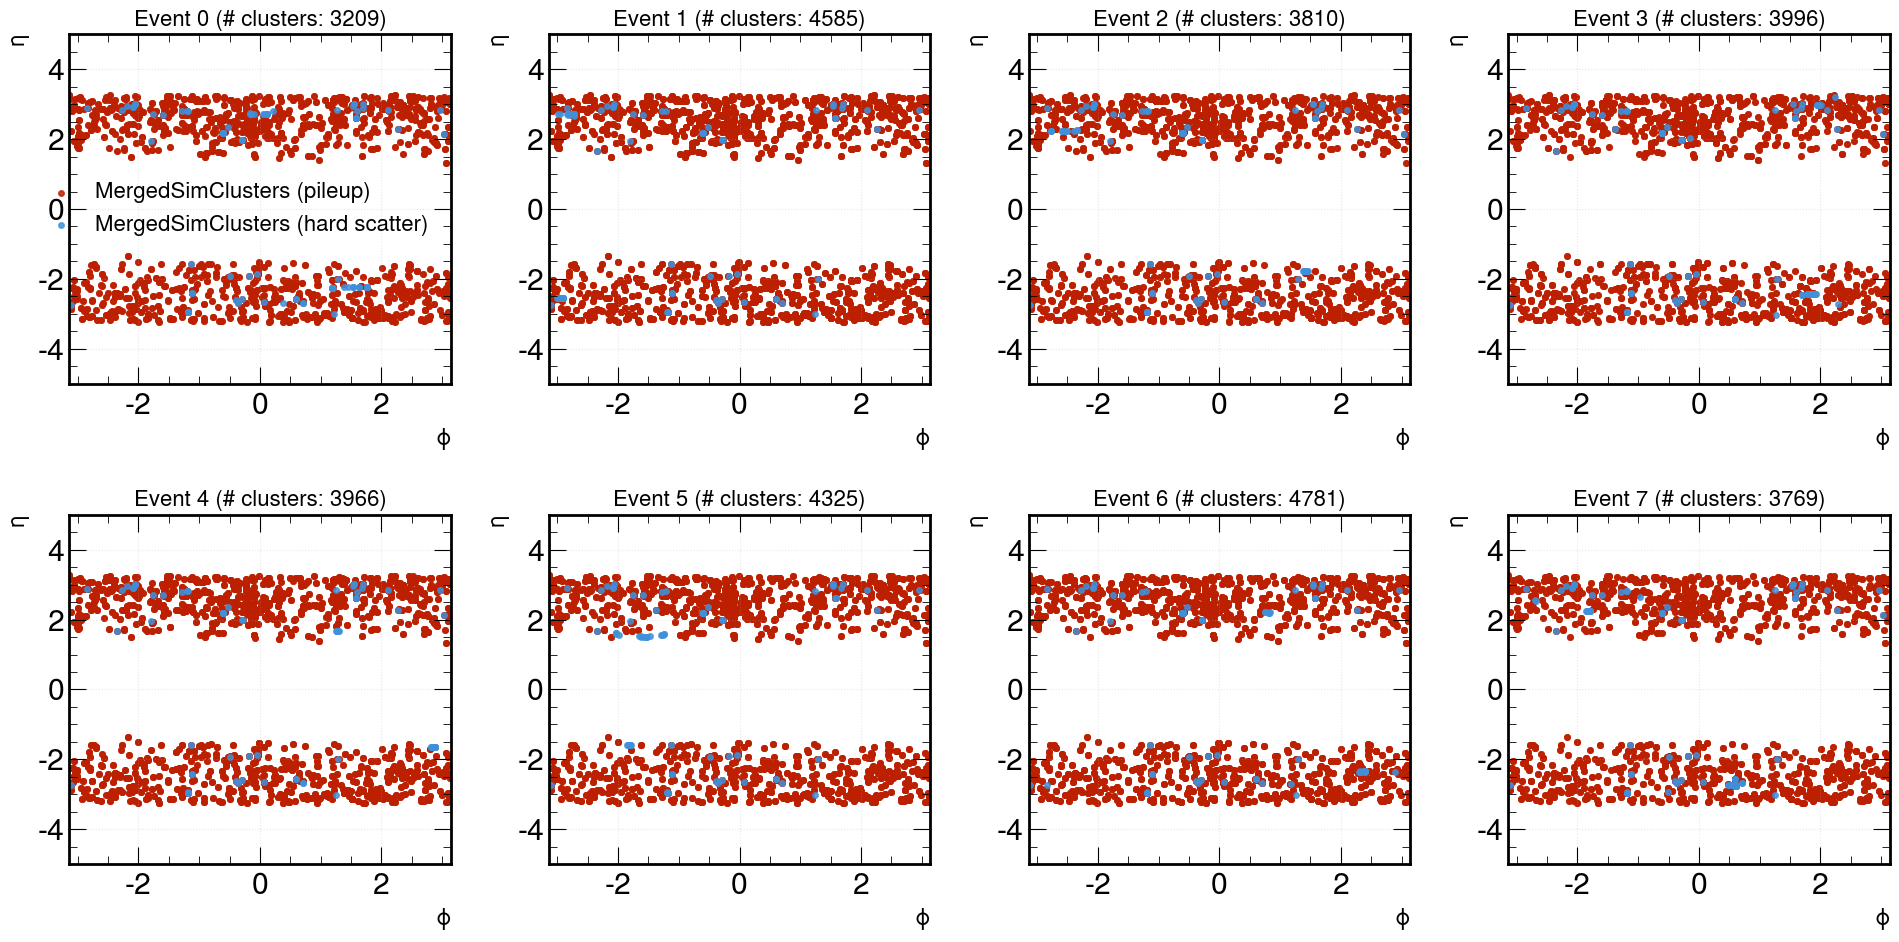

In [89]:
# Scatter plot of RecHitHGC eta vs phi and MergedSimCluster eta vs phi for first 10 events
num_events = 8
fontsize = 16
fig, axes = plt.subplots(2, num_events // 2, figsize=(num_events // 2 * 5, 10))
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Filter clusters below energy threshold (e.g. 0.01)
energy_threshold = 0.2

axes = axes.flatten()

for i in range(num_events):
    ax = axes[i]
    
    # Get RecHitHGC data for event i
    #rec_eta = events.RecHitHGC.eta[i]
    #rec_phi = events.RecHitHGC.phi[i]
    
    # Get MergedSimCluster data for event i
    clusters = events.MergedSimCluster[i]
    mask = clusters.boundaryEnergy > energy_threshold
    clusters = clusters[mask]
    merged_eta = clusters.impactPoint_eta
    merged_phi = clusters.impactPoint_phi
    
    # Plot RecHitHGC candidates with circles
    #ax.scatter(rec_phi, rec_eta, marker='o', s=50, alpha=1.0, 
    #           label='RecHitHGC Candidates', edgecolors=CMS_blue, color='none', linewidths=1.0)
    
    is_pileup = (clusters.eventId > 0) | (clusters.bunchCrossing > 0)

    # Plot MergedSimClusters with red crosses
    ax.scatter(merged_phi[is_pileup], merged_eta[is_pileup], marker='.', s=50, c=CMS_red, alpha=0.8, 
               label='MergedSimClusters (pileup)', linewidths=1.5)
    ax.scatter(merged_phi[~is_pileup], merged_eta[~is_pileup], marker='.', s=50, c=CMS_blue, alpha=0.8, 
               label='MergedSimClusters (hard scatter)', linewidths=1.5)
    ax.set_xlim(-3.14, 3.14)
    ax.set_ylim(-5, 5)
    ax.set_xlabel(r"$\phi$", fontsize=fontsize)
    ax.set_ylabel(r"$\eta$", fontsize=fontsize)
    ax.set_title(f'Event {i} (# clusters: {len(merged_eta)})', fontsize=fontsize)
    ax.grid(True, alpha=0.3)
    
    # Only show legend on first plot to avoid clutter
    if i == 0:
        ax.legend(fontsize=fontsize)

plt.tight_layout()
plt.show()

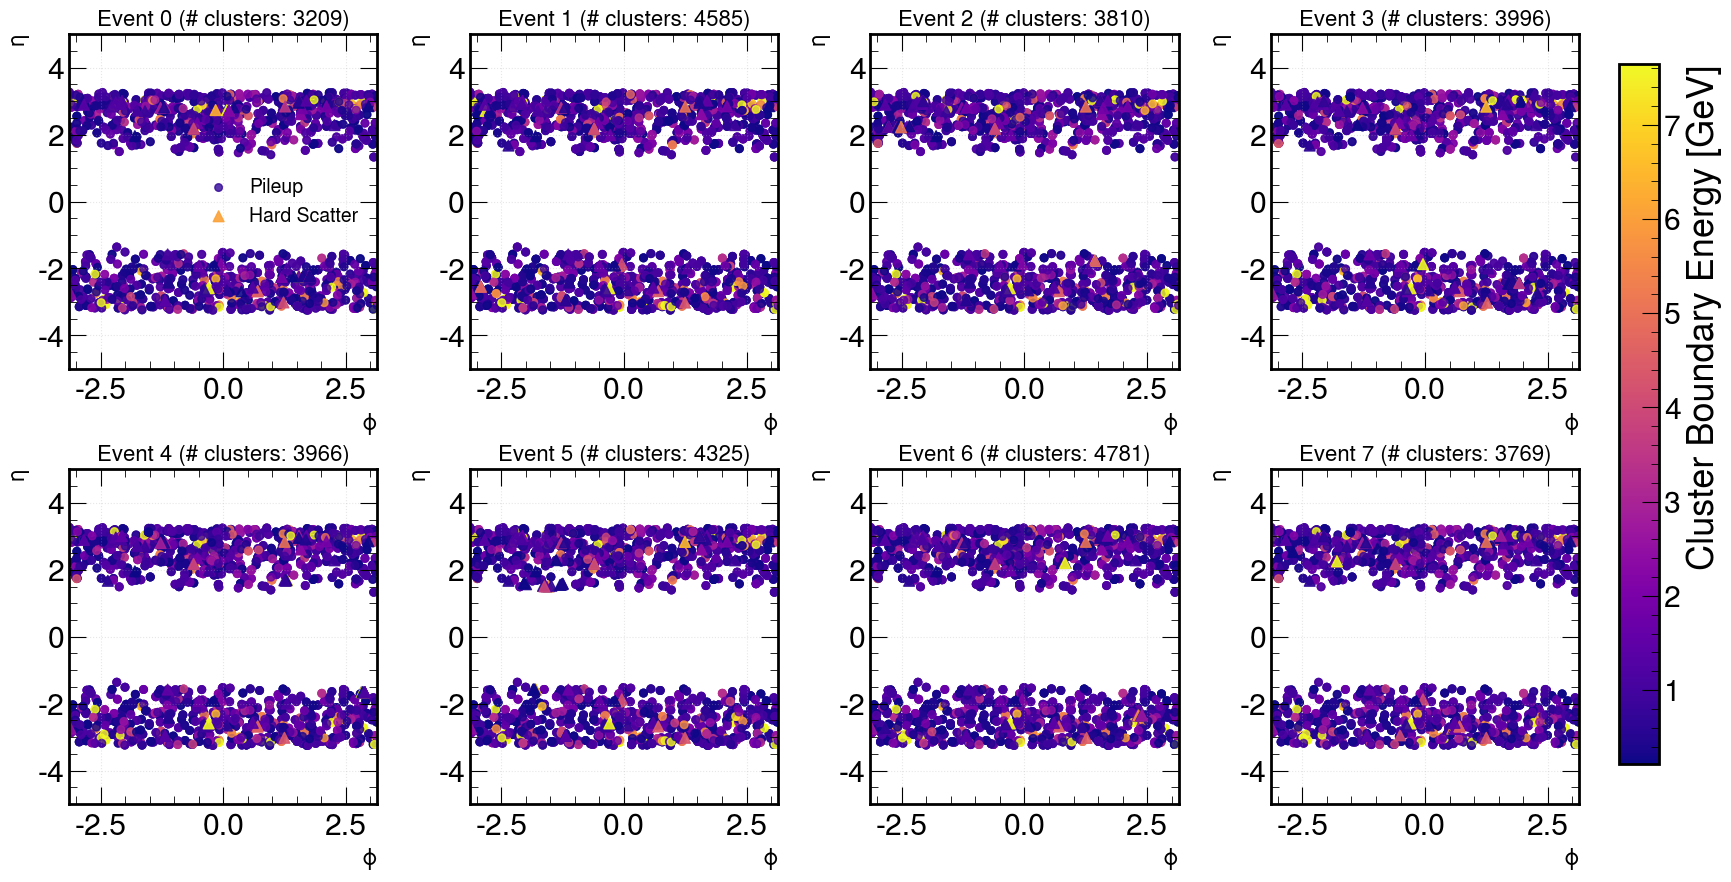

In [91]:

# Scatter plot of MergedSimCluster eta vs phi, colored by cluster energy, for first 8 events
num_events = 8
fontsize = 16
fig, axes = plt.subplots(2, num_events // 2, figsize=(num_events // 2 * 5, 10))
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Filter clusters below energy threshold
energy_threshold = 0.2

axes = axes.flatten()

# Determine global energy range for a consistent colormap across all subplots
all_energies = []
for i in range(num_events):
    clusters = events.MergedSimCluster[i]
    mask = clusters.boundaryEnergy > energy_threshold
    all_energies.append(ak.to_numpy(clusters.boundaryEnergy[mask]))
all_energies = np.concatenate(all_energies)
vmin = np.percentile(all_energies, 2)
vmax = np.percentile(all_energies, 98)

cmap = plt.cm.plasma
norm = plt.Normalize(vmin=vmin, vmax=vmax)

for i in range(num_events):
    ax = axes[i]

    clusters = events.MergedSimCluster[i]
    mask = clusters.boundaryEnergy > energy_threshold
    clusters = clusters[mask]
    merged_eta = ak.to_numpy(clusters.impactPoint_eta)
    merged_phi = ak.to_numpy(clusters.impactPoint_phi)
    energy = ak.to_numpy(clusters.boundaryEnergy)
    is_pileup = ak.to_numpy((clusters.eventId > 0) | (clusters.bunchCrossing > 0))

    # Pileup: circles
    ax.scatter(merged_phi[is_pileup], merged_eta[is_pileup],
               marker='o', s=30, c=energy[is_pileup], cmap=cmap, norm=norm,
               alpha=0.8, label='Pileup')
    # Hard scatter: triangles (larger to stay visible)
    ax.scatter(merged_phi[~is_pileup], merged_eta[~is_pileup],
               marker='^', s=60, c=energy[~is_pileup], cmap=cmap, norm=norm,
               alpha=0.9, label='Hard Scatter')

    ax.set_xlim(-3.14, 3.14)
    ax.set_ylim(-5, 5)
    ax.set_xlabel(r"$\phi$", fontsize=fontsize)
    ax.set_ylabel(r"$\eta$", fontsize=fontsize)
    ax.set_title(f'Event {i} (# clusters: {len(merged_eta)})', fontsize=fontsize)
    ax.grid(True, alpha=0.3)

    if i == 0:
        ax.legend(fontsize=fontsize - 2)

# Shared colorbar on the right
fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.70])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, cax=cbar_ax, label='Cluster Boundary Energy [GeV]')

plt.show()


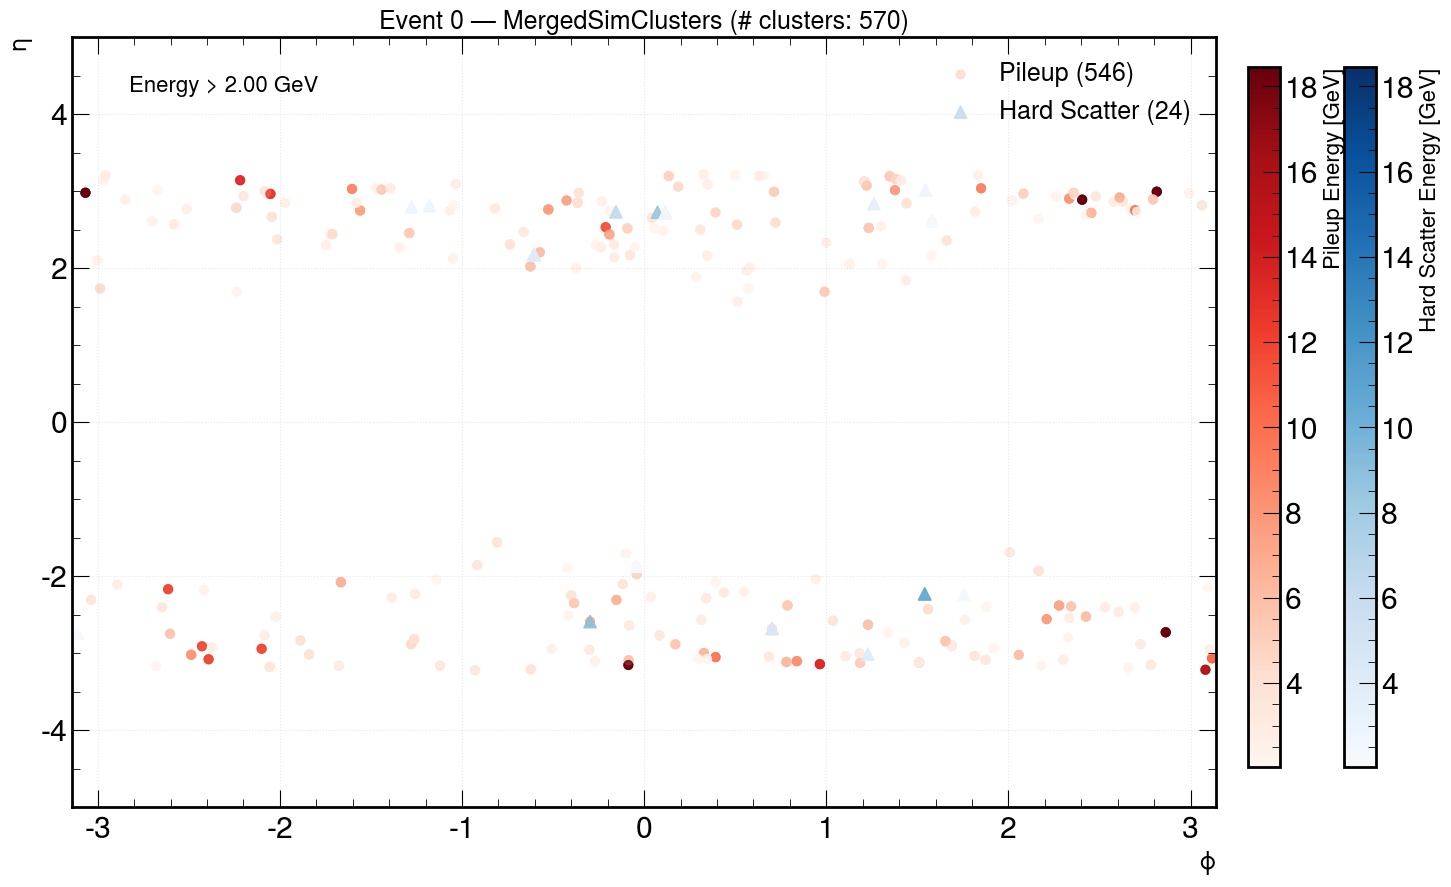

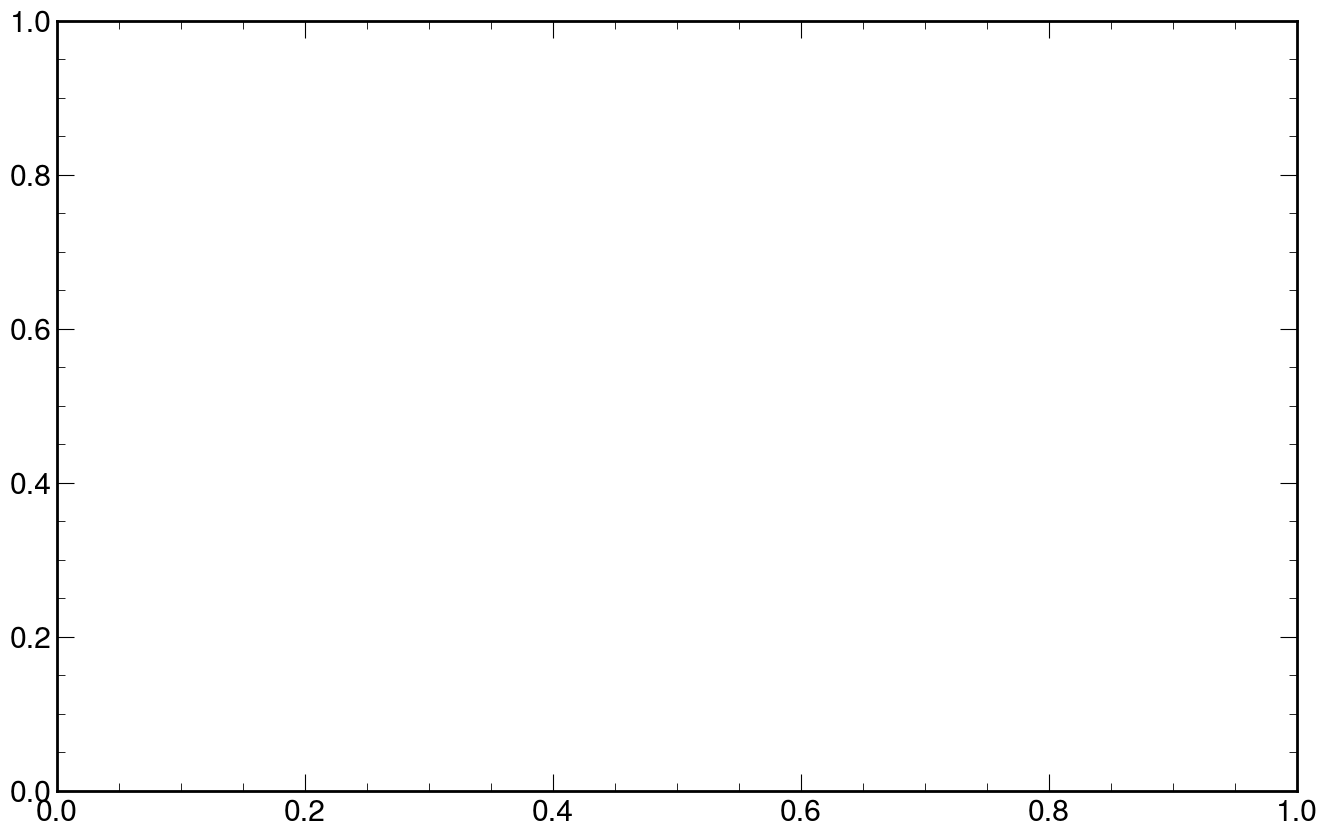

In [133]:
# Scatter plot of MergedSimCluster eta vs phi, colored by cluster energy, for a single event
ievt = 0
fontsize = 18
fig, ax = plt.subplots(figsize=(16, 10))

# Filter clusters below energy threshold
energy_threshold = 2.0

clusters = events.MergedSimCluster[ievt]
mask = clusters.boundaryEnergy > energy_threshold
clusters = clusters[mask]
merged_eta = ak.to_numpy(clusters.impactPoint_eta)
merged_phi = ak.to_numpy(clusters.impactPoint_phi)
energy = ak.to_numpy(clusters.boundaryEnergy)
is_pileup = ak.to_numpy((clusters.eventId > 0) | (clusters.bunchCrossing > 0))

vmin = np.percentile(energy, 2)
vmax = np.percentile(energy, 98)
cmap_pileup = plt.cm.Reds
cmap_hard_scatter = plt.cm.Blues
norm = plt.Normalize(vmin=vmin, vmax=vmax)

# Pileup: circles
ax.scatter(merged_phi[is_pileup], merged_eta[is_pileup],
           marker='o', s=40, c=energy[is_pileup], cmap=cmap_pileup, norm=norm,
           alpha=0.8, label=f'Pileup ({is_pileup.sum()})')
# Hard scatter: triangles
ax.scatter(merged_phi[~is_pileup], merged_eta[~is_pileup],
           marker='^', s=80, c=energy[~is_pileup], cmap=cmap_hard_scatter, norm=norm,
           alpha=0.9, label=f'Hard Scatter ({(~is_pileup).sum()})')

ax.set_xlim(-3.14, 3.14)
ax.set_ylim(-5, 5)
ax.set_xlabel(r"$\phi$", fontsize=fontsize)
ax.set_ylabel(r"$\eta$", fontsize=fontsize)
ax.set_title(f'Event {ievt} — MergedSimClusters (# clusters: {len(merged_eta)})', fontsize=fontsize)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=fontsize)

# Add text box on the left with mean and std dev, min and max of the event weight
props = dict(boxstyle="round", facecolor="white", alpha=0.0)
stats_textstr = (
    f"Energy > {energy_threshold:.2f} GeV\n"
)
ax.text(0.05, 0.95, stats_textstr, transform=ax.transAxes, fontsize=16, verticalalignment="top", horizontalalignment="left", bbox=props)

# Two colorbars side by side: red (pileup) and blue (hard scatter)
fig.subplots_adjust(right=0.84)
cbar_ax_red  = fig.add_axes([0.86, 0.15, 0.02, 0.70])
cbar_ax_blue = fig.add_axes([0.92, 0.15, 0.02, 0.70])

cb_red = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap_pileup, norm=norm), cax=cbar_ax_red)
cb_red.set_label('Pileup Energy [GeV]', fontsize=fontsize - 2)

cb_blue = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap_hard_scatter, norm=norm), cax=cbar_ax_blue)
cb_blue.set_label('Hard Scatter Energy [GeV]', fontsize=fontsize - 2)

# Plot 
fig, ax = plt.subplots(figsize=(16, 10))


plt.show()


<Array [[], [], [], [], ... [], [], [], []] type='10 * var * float32[parameters=...'>

11.242963977112744 +- 21.6
Single-hit MergedSimClusters: 27.3%
Less than 5 hits: 55.2%
Less than 10 hits: 70.4%


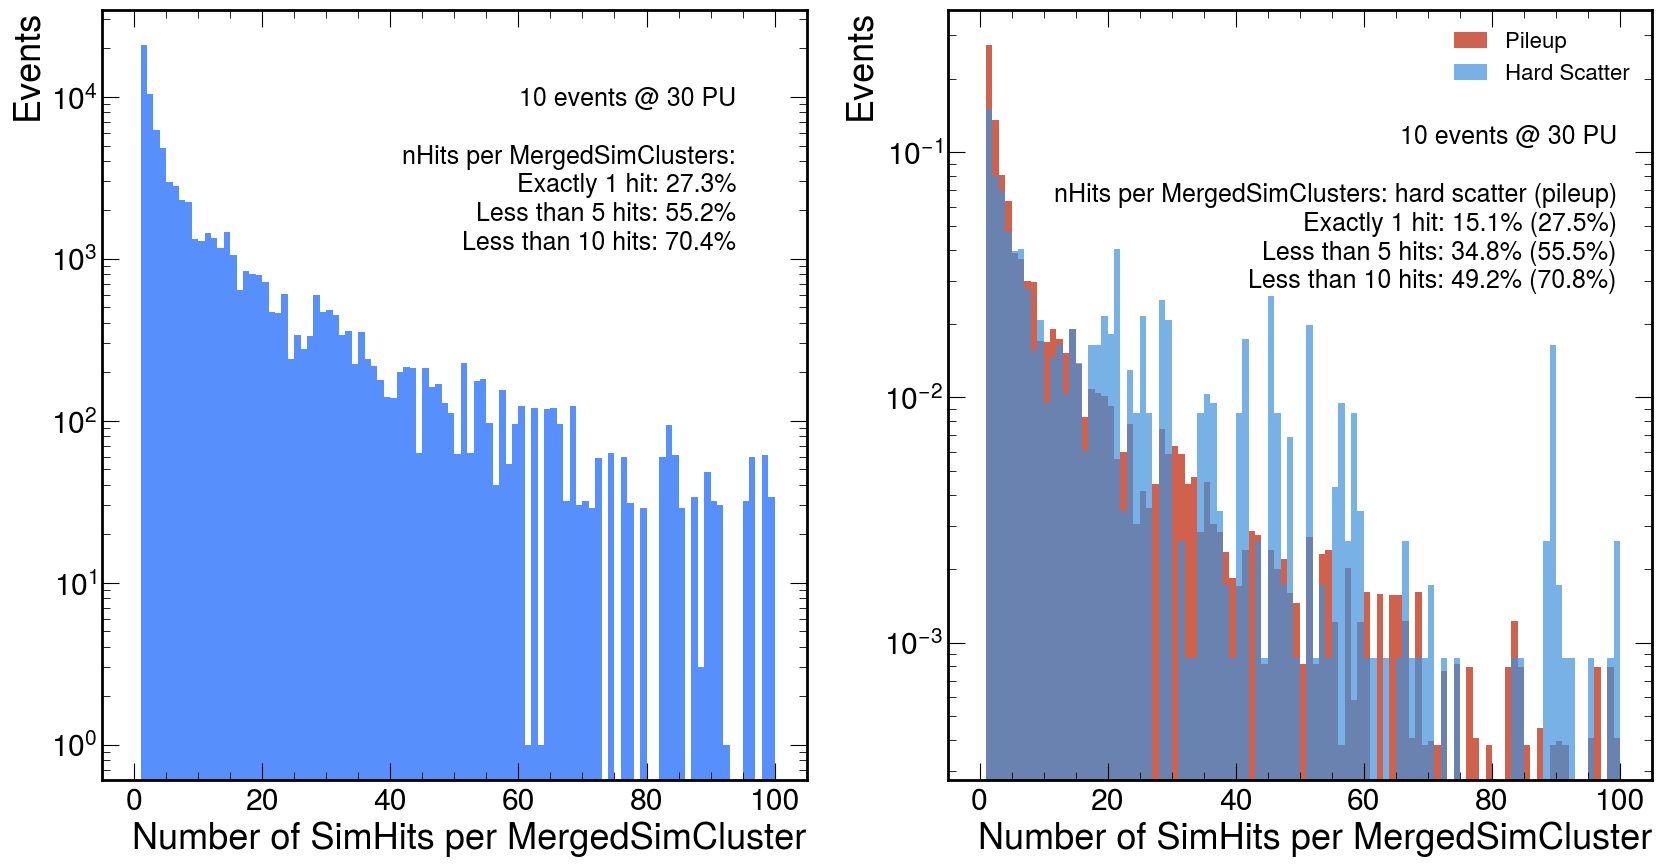

In [28]:
# Plot number of hits per MergedSimCluster
nhits_per_cluster = events.MergedSimCluster.nHits
is_pileup = (events.MergedSimCluster.eventId != 0) | (events.MergedSimCluster.bunchCrossing != 0)
print(np.mean(nhits_per_cluster), '+-', round(np.std(nhits_per_cluster), 1))
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
n, bins, patches = ax[0].hist(ak.flatten(nhits_per_cluster), bins=100, range=(0, 100))
single_hit_fraction = n[1] / np.sum(n)
# compute fraction of MergedSimClusters with less than 5 hits
less_than_5_fraction = np.sum(n[:5]) / np.sum(n)
less_than_10_fraction = np.sum(n[:10]) / np.sum(n)
ax[0].set_xlabel("Number of SimHits per MergedSimCluster")
ax[0].set_ylabel("Events")
ax[0].set_yscale("log")
ax[0].text(
    0.9,
    0.9,
    "10 events @ 30 PU\n\nnHits per MergedSimClusters:\nExactly 1 hit: {:.1%}".format(single_hit_fraction) + "\nLess than 5 hits: {:.1%}".format(less_than_5_fraction) + "\nLess than 10 hits: {:.1%}".format(less_than_10_fraction),
    transform=ax[0].transAxes,
    ha="right",
    va="top",
    fontsize=18,
)

# Plot distribution of nHits for pileup and hard scatter MergedSimClusters separately (density plot to better compare shapes)
n_pileup, bins, patches = ax[1].hist(ak.flatten(nhits_per_cluster[is_pileup]), bins=100, range=(0, 100), alpha=0.7, label='Pileup', color=CMS_red, density=True)
n_hard_scatter, bins, patches = ax[1].hist(ak.flatten(nhits_per_cluster[~is_pileup]), bins=100, range=(0, 100), alpha=0.7, label='Hard Scatter', color=CMS_blue, density=True)
ax[1].set_xlabel("Number of SimHits per MergedSimCluster")
ax[1].set_ylabel("Events")
ax[1].set_yscale("log")
ax[1].legend(fontsize=16)
single_hit_fraction_pileup = n_pileup[1] / np.sum(n_pileup)
single_hit_fraction_hard_scatter = n_hard_scatter[1] / np.sum(n_hard_scatter)
less_than_5_fraction_pileup = np.sum(n_pileup[:5]) / np.sum(n_pileup)
less_than_5_fraction_hard_scatter = np.sum(n_hard_scatter[:5]) / np.sum(n_hard_scatter)
less_than_10_fraction_pileup = np.sum(n_pileup[:10]) / np.sum(n_pileup)
less_than_10_fraction_hard_scatter = np.sum(n_hard_scatter[:10]) / np.sum(n_hard_scatter)
ax[1].text(
    0.95,
    0.85,
    "10 events @ 30 PU\n\nnHits per MergedSimClusters: hard scatter (pileup)\nExactly 1 hit: {:.1%} ({:.1%})".format(single_hit_fraction_hard_scatter, single_hit_fraction_pileup) + "\nLess than 5 hits: {:.1%} ({:.1%})".format(less_than_5_fraction_hard_scatter, less_than_5_fraction_pileup) + "\nLess than 10 hits: {:.1%} ({:.1%})".format(less_than_10_fraction_hard_scatter, less_than_10_fraction_pileup),
    transform=ax[1].transAxes,
    ha="right",
    va="top",
    fontsize=18,
)

# Compute fraction of MergedSimClusters with just one hit
print("Single-hit MergedSimClusters: {:.1%}".format(single_hit_fraction))
print("Less than 5 hits: {:.1%}".format(less_than_5_fraction))
print("Less than 10 hits: {:.1%}".format(less_than_10_fraction))

10.04228542273827 +- 18.6
Single-hit SimClusters: 27.7%
Less than 5 hits: 56.9%
Less than 10 hits: 72.8%


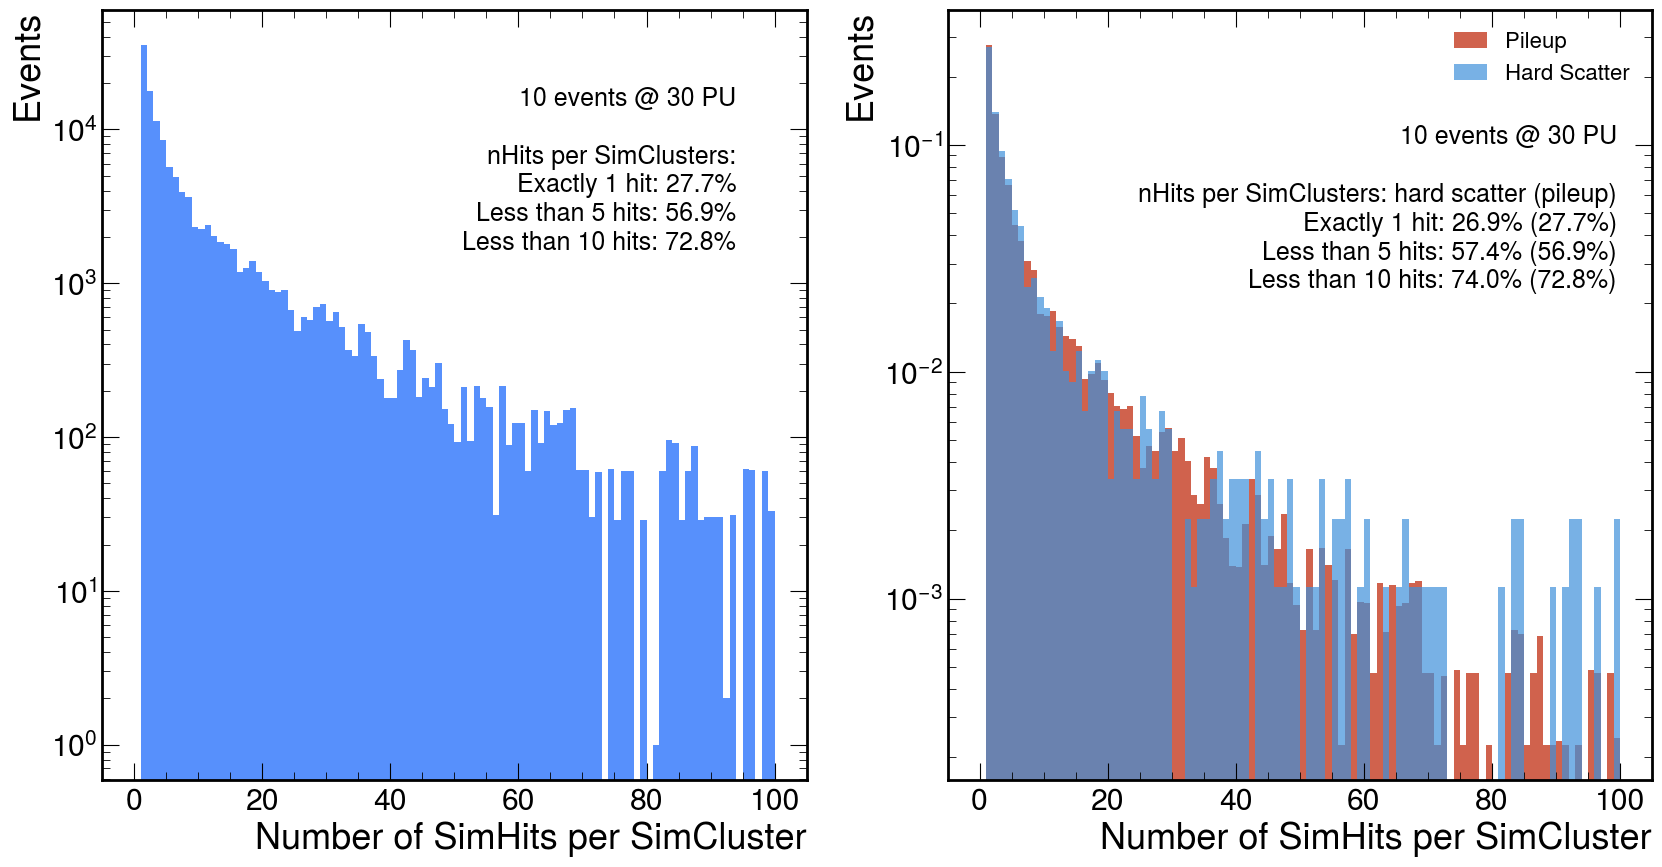

In [59]:
# Plot number of hits per SimCluster
nhits_per_cluster = events.SimCluster.nHits
is_pileup = (events.SimCluster.eventId != 0) | (events.SimCluster.bunchCrossing != 0)
print(np.mean(nhits_per_cluster), '+-', round(np.std(nhits_per_cluster), 1))
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
n, bins, patches = ax[0].hist(ak.flatten(nhits_per_cluster), bins=100, range=(0, 100))
single_hit_fraction = n[1] / np.sum(n)
# compute fraction of MergedSimClusters with less than 5 hits
less_than_5_fraction = np.sum(n[:5]) / np.sum(n)
less_than_10_fraction = np.sum(n[:10]) / np.sum(n)
ax[0].set_xlabel("Number of SimHits per SimCluster")
ax[0].set_ylabel("Events")
ax[0].set_yscale("log")
ax[0].text(
    0.9,
    0.9,
    "10 events @ 30 PU\n\nnHits per SimClusters:\nExactly 1 hit: {:.1%}".format(single_hit_fraction) + "\nLess than 5 hits: {:.1%}".format(less_than_5_fraction) + "\nLess than 10 hits: {:.1%}".format(less_than_10_fraction),
    transform=ax[0].transAxes,
    ha="right",
    va="top",
    fontsize=18,
)

# Plot distribution of nHits for pileup and hard scatter SimClusters separately (density plot to better compare shapes)
n_pileup, bins, patches = ax[1].hist(ak.flatten(nhits_per_cluster[is_pileup]), bins=100, range=(0, 100), alpha=0.7, label='Pileup', color=CMS_red, density=True)
n_hard_scatter, bins, patches = ax[1].hist(ak.flatten(nhits_per_cluster[~is_pileup]), bins=100, range=(0, 100), alpha=0.7, label='Hard Scatter', color=CMS_blue, density=True)
ax[1].set_xlabel("Number of SimHits per SimCluster")
ax[1].set_ylabel("Events")
ax[1].set_yscale("log")
ax[1].legend(fontsize=16)
single_hit_fraction_pileup = n_pileup[1] / np.sum(n_pileup)
single_hit_fraction_hard_scatter = n_hard_scatter[1] / np.sum(n_hard_scatter)
less_than_5_fraction_pileup = np.sum(n_pileup[:5]) / np.sum(n_pileup)
less_than_5_fraction_hard_scatter = np.sum(n_hard_scatter[:5]) / np.sum(n_hard_scatter)
less_than_10_fraction_pileup = np.sum(n_pileup[:10]) / np.sum(n_pileup)
less_than_10_fraction_hard_scatter = np.sum(n_hard_scatter[:10]) / np.sum(n_hard_scatter)
ax[1].text(
    0.95,
    0.85,
    "10 events @ 30 PU\n\nnHits per SimClusters: hard scatter (pileup)\nExactly 1 hit: {:.1%} ({:.1%})".format(single_hit_fraction_hard_scatter, single_hit_fraction_pileup) + "\nLess than 5 hits: {:.1%} ({:.1%})".format(less_than_5_fraction_hard_scatter, less_than_5_fraction_pileup) + "\nLess than 10 hits: {:.1%} ({:.1%})".format(less_than_10_fraction_hard_scatter, less_than_10_fraction_pileup),
    transform=ax[1].transAxes,
    ha="right",
    va="top",
    fontsize=18,
)

# Compute fraction of SimClusters with just one hit
print("Single-hit SimClusters: {:.1%}".format(single_hit_fraction))
print("Less than 5 hits: {:.1%}".format(less_than_5_fraction))
print("Less than 10 hits: {:.1%}".format(less_than_10_fraction))

In [29]:
events.SimCluster.nHits

<Array [[114, 1, 5, 3, 3, ... 5, 1, 6, 3, 1]] type='10 * var * int32[parameters=...'>

In [30]:
events.MergedSimCluster.nHits

<Array [[124, 5, 3, 3, 3, ... 14, 1, 5, 1, 6]] type='10 * var * int32[parameters...'>

/tmp/ipykernel_15919/2539500119.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend();


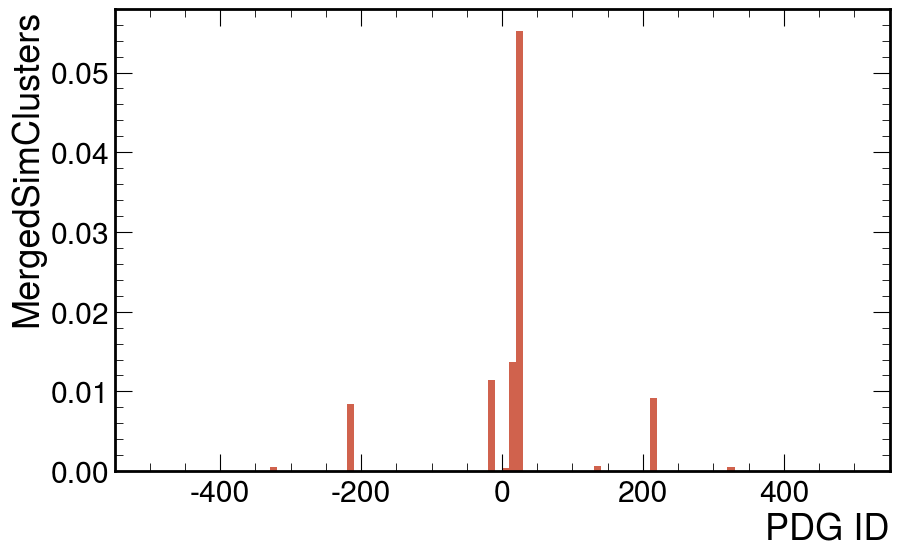

In [115]:
pdgId = events.MergedSimCluster.pdgId
# Plot the event IDs of the SimClusters
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(ak.flatten(pdgId), bins=100, range=(-500, 500), alpha=0.7, color=CMS_red, density=True)
ax.set_xlabel("PDG ID")
ax.set_ylabel("MergedSimClusters")
ax.legend();

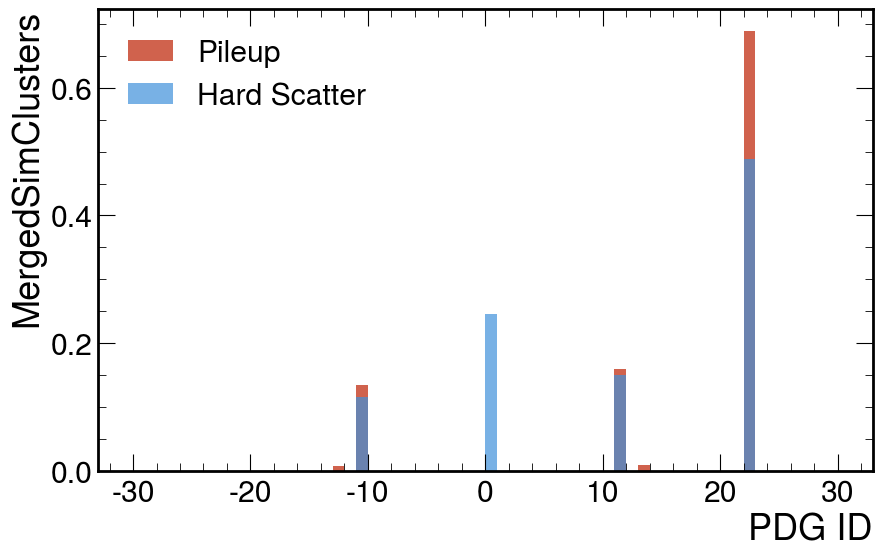

In [ ]:
pdgId = events.MergedSimCluster.pdgId
is_pileup = (events.MergedSimCluster.eventId > 0) | (events.MergedSimCluster.bunchCrossing > 0)
# Plot the event IDs of the SimClusters
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(ak.flatten(pdgId[is_pileup]), bins=60, range=(-30, 30), label="Pileup", alpha=0.7, color=CMS_red, density=True)
ax.hist(ak.flatten(pdgId[~is_pileup]), bins=60, range=(-30, 30), label="Hard Scatter", alpha=0.7, color=CMS_blue, density=True)
ax.set_xlabel("PDG ID")
ax.set_ylabel("MergedSimClusters")
ax.legend();

In [32]:
events.MergedSimCluster.eventId[0].tolist()

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,


Text(0, 1, 'MergedSimClusters')

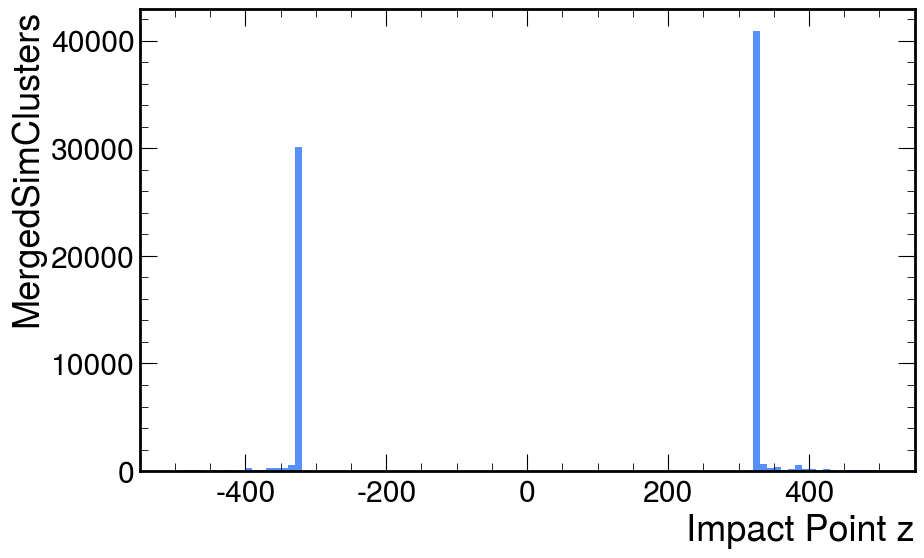

In [58]:
z = events.MergedSimCluster.impactPoint_z
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(ak.flatten(z), bins=100, range=(-500, 500))
ax.set_xlabel("Impact Point z")
ax.set_ylabel("MergedSimClusters")

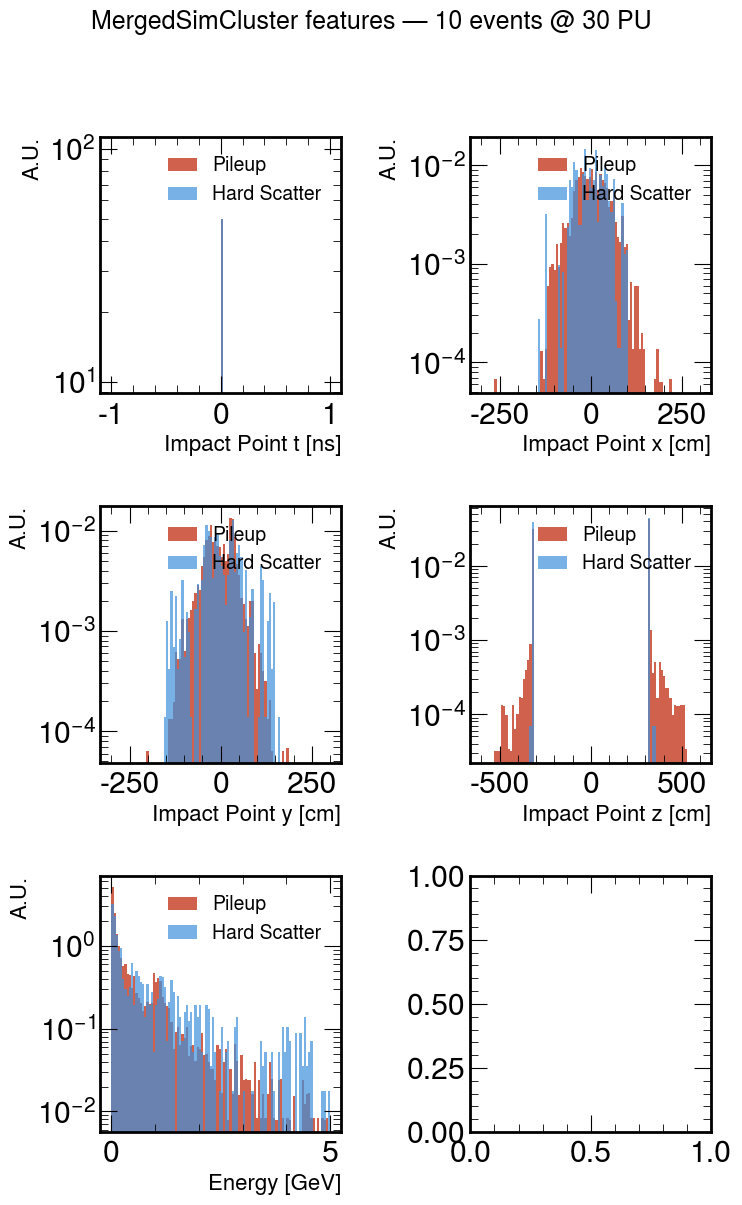

In [127]:
# 1D histograms of MergedSimCluster features: pileup (red) vs hard scatter (blue)
is_pileup = (events.MergedSimCluster.eventId > 0) | (events.MergedSimCluster.bunchCrossing > 0)

features = [
    ("impactPoint_t", "Impact Point t [ns]",   (-1,   1)),
    ("impactPoint_x", "Impact Point x [cm]",   (-300, 300)),
    ("impactPoint_y", "Impact Point y [cm]",   (-300, 300)),
    ("impactPoint_z", "Impact Point z [cm]",   (-600, 600)),
    ("boundaryEnergy",       "Energy [GeV]",   (0,    5)),
]

fontsize = 16
nbins = 100
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
plt.subplots_adjust(wspace=0.35)

axes = axes.flatten()

for ax, (field, xlabel, (xlo, xhi)) in zip(axes, features):
    values = getattr(events.MergedSimCluster, field)
    vals_pu = ak.to_numpy(ak.flatten(values[is_pileup]))
    vals_hs = ak.to_numpy(ak.flatten(values[~is_pileup]))

    ax.hist(vals_pu, bins=nbins, range=(xlo, xhi), alpha=0.7,
            color=CMS_red,  label='Pileup',        density=True)
    ax.hist(vals_hs, bins=nbins, range=(xlo, xhi), alpha=0.7,
            color=CMS_blue, label='Hard Scatter',   density=True)
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel("A.U.", fontsize=fontsize)
    ax.set_yscale("log")
    ax.legend(fontsize=fontsize - 2)

plt.suptitle("MergedSimCluster features — 10 events @ 30 PU", fontsize=fontsize + 2, y=1.02)
plt.tight_layout()
plt.show()


In [128]:
import coffea
coffea.__version__

'0.7.29'